# Applied Statistical Inference - Tutorial 0

Chris Hallsworth

2026-10-01

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import expon, norm
from IPython.display import Markdown, display


def ppoints(n):
    # The plotting positions used by R's ppoints().
    a = 3 / 8 if n <= 10 else 1 / 2
    return (np.arange(1, n + 1) - a) / (n + 1 - 2 * a)

# Introduction

This tutorial aims to revise topics covered in earlier statistics modules. We'll draw the ideas together by exploring a dataset in detail. We'll also give a brief illustration of some ideas that will be covered in more detail during the module.

In what follows, we will

- Demonstrate maximum likelihood estimation
- Illustrate asymptotic normality of MLEs
- Introduce the idea of the bootstrap

The idea of maximum likelihood estimation, and the asymptotic properties of maximum likelihood estimators, should be familiar from earlier work. The bootstrap might be new to you: we'll say more about it in lectures.

You're not expected to know all of the Python functions that we're using below. All of these are well-documented, and you are very welcome to ask about Python practicalities on EdStem or during the lectures.

# The data
The [British Geological Survey](https://earthquakes.bgs.ac.uk/) provide data on historic UK seismic activity. The data file provided includes a year's worth of data (from 2022 - 3) covering the area from 49 to 63 degrees latitude and -12 to 5 degrees longitude. You can download the [exact data file](https://earthquakes.bgs.ac.uk/cgi-bin/get_events?lat1=49&lat2=63&lon1=-12&lon2=5&lat0=&lon0=&radius=&date1=2022-01-12&date2=2023-01-7&dep1=&dep2=&mag1=&mag2=&nsta1=&nsta2=&output=csv), or [get your own data ](https://earthquakes.bgs.ac.uk/earthquakes/dataSearch.html) for a time period and region of your choice.

First read in the data. You'll need to make sure the path matches where you put the file.

In [21]:
bgs = pd.read_csv("bgs-2023.csv", skipinitialspace=True)

In [22]:
bgs

,yyyy-mm-dd,hh:mm:ss.ss,lat,lon,depth,ML,Nsta,RMS,intensity,induced,locality
0,2022-01-16,22:46:22,61.043,3.832,10.0,1.8,3,0.3,NaN,NaN,NORWEGIAN SEA
1,2022-01-17,04:55:54,53.603,-2.984,7.7,1.1,9,0.3,NaN,NaN,SOUTHPORT MERSEYSIDE
2,2022-01-18,22:05:02,52.242,1.673,16.6,1.0,4,0.2,NaN,NaN,SOUTHERN NORTH SEA
3,2022-01-19,12:33:03,61.327,3.343,10.0,2.0,3,0.4,NaN,NaN,NORWEGIAN SEA
4,2022-01-19,20:32:18,55.792,-5.741,14.4,1.1,8,0.1,NaN,NaN,SOUND OF JURA
...,...,...,...,...,...,...,...,...,...,...,...
279,2022-12-30,03:03:55,56.631,-5.677,8.7,0.9,5,0.2,NaN,NaN,STRONTIAN HIGHLAND
280,2023-01-01,03:48:59,57.217,-6.210,2.6,0.9,4,0.2,NaN,NaN,SKYE HIGHLAND
281,2023-01-02,21:06:19,54.265,-2.487,7.6,1.3,14,0.4,NaN,NaN,GAWTHROP CUMBRIA
282,2023-01-03,06:20:44,56.383,-5.853,2.2,1.7,9,0.3,3.0,NaN,MULL ARGYLL & BUTE


Then make a single date-time object by combining the first two columns

In [23]:
bgs["dt"] = pd.to_datetime(
    bgs["yyyy-mm-dd"].astype(str).str.strip()
    + " "
    + bgs["hh:mm:ss.ss"].astype(str).str.strip(),
    format="%Y-%m-%d %H:%M:%S",
)

Define a new variable, which is the time difference in seconds between successive earthquakes

In [24]:
inter_eq_times = bgs["dt"].diff().dt.total_seconds().iloc[1:].to_numpy()

In what follows we will just be concerned with the `inter_eq_times`.

# A probability model

We'll make a simple model for the occurrence of (detected) earthquakes in time.

The exponential distribution is often used for waiting times

$$ f_Y(y; \lambda) = \lambda \exp(-\lambda y), \qquad y > 0, \lambda > 0. $$

Here we have chosen to parameterize the distribution using its rate $\lambda$.

***
__Questions:__

1. What are the units of $\lambda$?
2. What assumptions about the occurrence of earthquakes are implied by the chosen model? Considering the scale of our data, are they reasonable? How can we check?

__Solutions__

<details><summary>show solutions </summary>

1. When time is measured in seconds, $\lambda$ has units $1/sec$.
2. The exponential distribution implies a 'memoryless' property, i.e. a model in which earthquakes occur randomly in time. For any small region, one can think of physical reasons why this would not be a good model: Earthquakes are sudden releases of energy as a result of stress that has built up in a localized area. Smaller aftershocks typically occur shortly a large earthquake. Once stress has been released after a series of substantial earthquakes, a 'refractory period' without earthquakes could be expected, while stress builds up.

However, our data refer to a large area over only a year: we are unlikely to be able to see these more subtle effects without incorporating location information. Looking at the marginal distribution of inter-activity times (i.e. ignoring location information), a "random arrivals" model does not seem unreasonable. We'll evaluate the model in what follows.

</details>

***

# Exploratory plots

We start by making an exploratory histogram

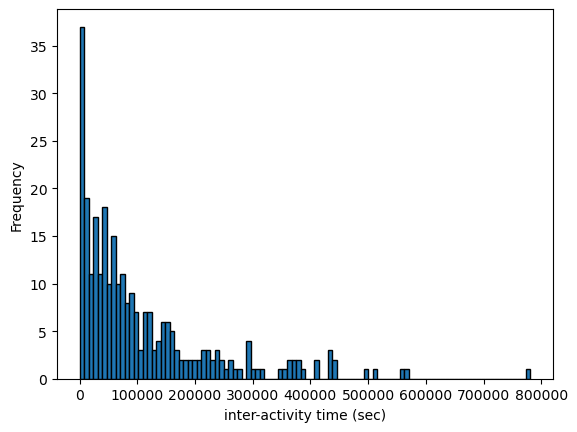

In [25]:
fig, ax = plt.subplots()
ax.hist(inter_eq_times, bins=100, edgecolor="black")
ax.set_xlabel("inter-activity time (sec)")
ax.set_ylabel("Frequency")
plt.show()

Given the scale of the data, it will be cleaner to measure the inter-activity time in days,

In [26]:
inter_eq_days = inter_eq_times / (60 * 60 * 24)

The histogram scale is now easier to read at a glance.

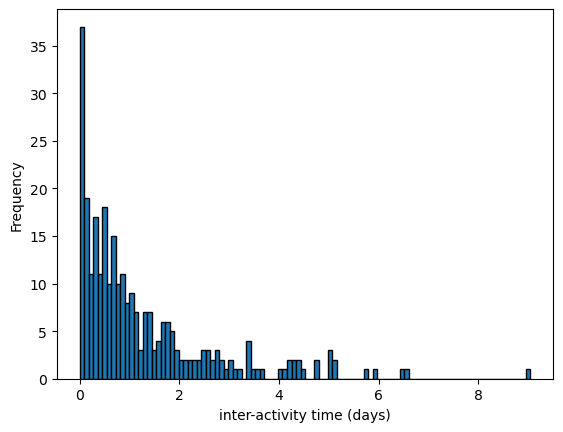

In [27]:
fig, ax = plt.subplots()
ax.hist(inter_eq_days, bins=100, edgecolor="black")
ax.set_xlabel("inter-activity time (days)")
ax.set_ylabel("Frequency")
plt.show()

The plot might look better with a different number of bins. [**Question:** What does 'better' mean?]

Here it is with approximately 30 bins.

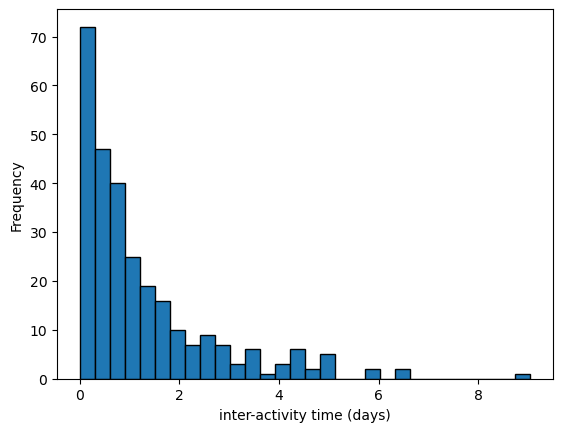

In [28]:
fig, ax = plt.subplots()
ax.hist(inter_eq_days, bins=30, edgecolor="black")
ax.set_xlabel("inter-activity time (days)")
ax.set_ylabel("Frequency")
plt.show()

# Estimating the model parameter

Our simple model has a single free parameter, $\lambda$. How do we estimate it from the data?

When we have a probability model, the *likelihood principle* gives us the answer. This states that all information in the data about the parameters is contained in the likelihood function $L(\lambda)$, i.e. the probability distribution of the observed data, regarded as a function of the free parameters.

The value of $\lambda$ at which $L$ achieves a maximum is a natural estimate.

For this model, we get

$$ \widehat{\lambda} = \frac{n}{\sum_{i=1}^n y_i} = \frac{1}{\bar{y}}.$$

***
**Recommended exercise:** You should be able to derive this expression, and explain why it is plausible in the data context.

<details> <summary> Show derivation of maximum likelihood estimator </summary>

$$ L(\lambda) = \prod_{i=1}^n \lambda \exp(-\lambda y_i ) = \lambda^n \exp\left( - \lambda\sum_{i=1} ^n y_i\right), $$

so that

$$  l(\lambda) = n \log \lambda - \lambda \sum_{i=1} ^n y_i $$
giving the derivative of $l$ as 
$$ \frac{\partial l(\lambda)}{\partial \lambda} =  \frac{n}{\lambda} - \sum_{i=1} ^n y_i.   $$

This is zero where $\lambda = \frac{1}{\bar{y}}$ as claimed.

The second derivative is

$$ \frac{\partial l^2(\lambda)}{\partial \lambda^2} = -\frac{n}{\lambda^2},  $$

which is negative, so that $\widehat{\lambda}$ is a maximum as expected.

Intuitively, $\lambda$ is the rate of arrivals, so the reciprocal relationship with the mean makes sense: higher mean time implies a lower rate of arrivals per unit time. 
</details>

***  
<br>

We now obtain the estimate for our particular dataset

In [29]:
lambda_hat = 1 / np.mean(inter_eq_days)

The estimated arrival rate seems reasonable, given the histogram above. It also fits with having observed the given number of events over a 1 year period.

# Evaluating the model

Compare our fitted model with the data, using a Q-Q plot.

To do this, we plot the order statistics, i.e. the observations sorted in ascending order, against the quantiles of the exponential distribution. `ppoints` gives equally spaced points between 0 and 1, which we pass to `expon.ppf`, the quantile function for the exponential distribution.

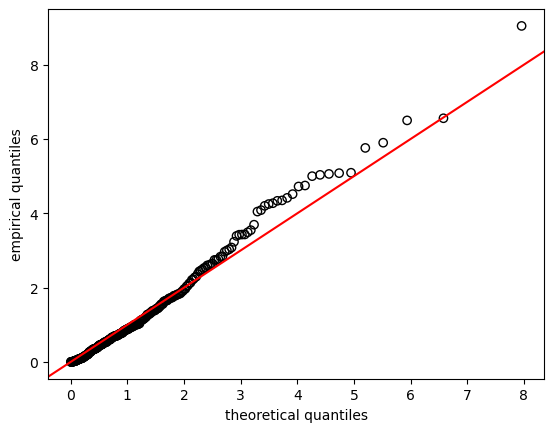

In [30]:
n_times = len(inter_eq_days)
p_pts = ppoints(n_times)

fig, ax = plt.subplots()
ax.scatter(
    expon.ppf(p_pts, scale=1 / lambda_hat),
    np.sort(inter_eq_days),
    facecolors="none", edgecolors="black",
)
ax.set_xlabel("theoretical quantiles")
ax.set_ylabel("empirical quantiles")
ax.axline((0, 0), slope=1, color="red")
plt.show()

Good agreement most of the way through the distribution. The right tail does not match so well, but is this surprising?

Can easily see how much departure we would expect if we had used data genuinely sampled from the probability model.

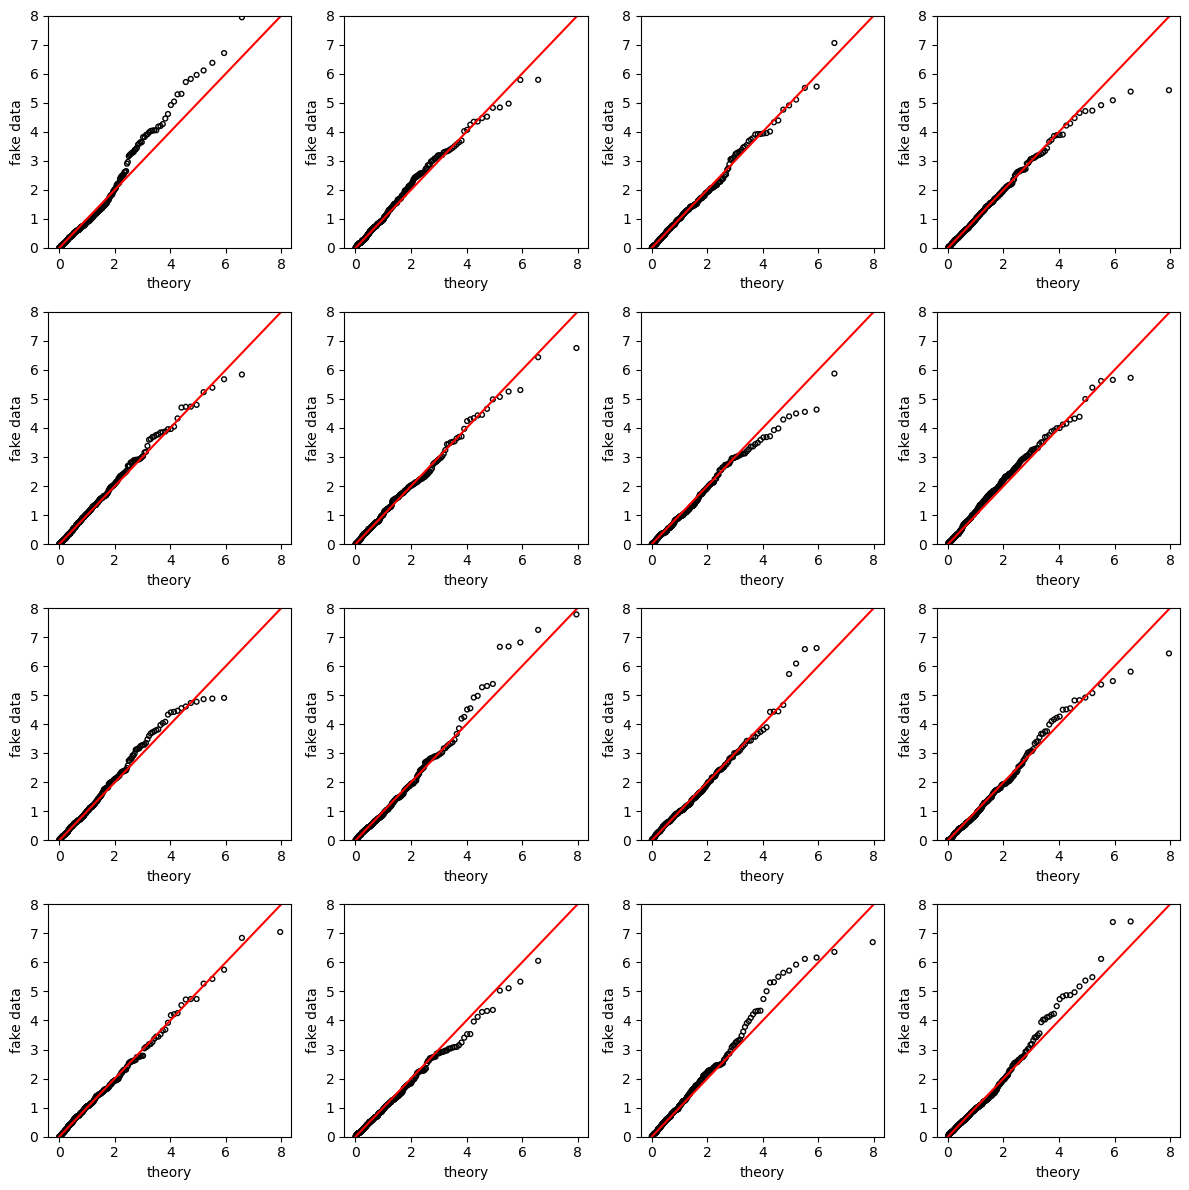

In [31]:
fig, axes = plt.subplots(4, 4, figsize=(12, 12))  # 4x4 grid of plots
rng = np.random.default_rng(555)  # ensure reproducibility
for ax in axes.flat:
    fake_data = rng.exponential(scale=1 / lambda_hat, size=n_times)
    ax.scatter(
        expon.ppf(p_pts, scale=1 / lambda_hat),
        np.sort(fake_data),
        facecolors="none", edgecolors="black", s=12,
    )
    ax.set_xlabel("theory")
    ax.set_ylabel("fake data")
    ax.set_ylim(0, 8)
    ax.axline((0, 0), slope=1, color="red")
fig.tight_layout()
plt.show()

In the 16 fake data samples, we do see departures from the identity line in the tail of the distribution, though they are not usually as large as in the observed data. Evidently the model fit is not perfect, though it is not outrageously bad. We could evaluate this more formally by using the [Kolmogorov-Smirnov test](https://en.wikipedia.org/wiki/Kolmogorov%E2%80%93Smirnov_test).

# Displaying the model fit

Add the probability density of our fitted model to a histogram

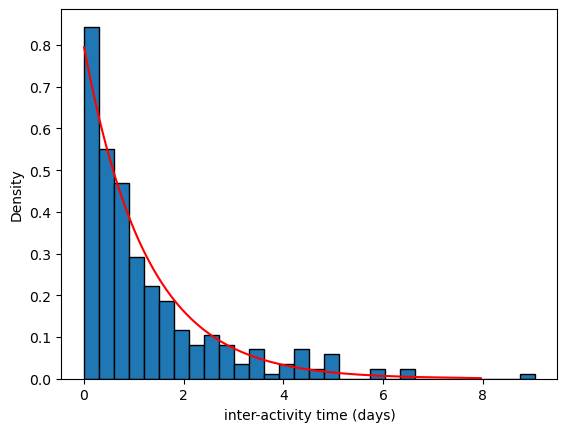

In [32]:
fig, ax = plt.subplots()
ax.hist(inter_eq_days, bins=30, density=True, edgecolor="black")
ax.set_xlabel("inter-activity time (days)")
ax.set_ylabel("Density")
x_pts = expon.ppf(p_pts, scale=1 / lambda_hat)
ax.plot(x_pts, expon.pdf(x_pts, scale=1 / lambda_hat), color="red")
plt.show()

The fit to the histogram seems reasonable, though it overestimates the proportion of inter-activity times around 2 days and underestimates the proportion of larger inter-activity times.

# Uncertainty in $\widehat{\lambda}$

Now, we illustrate the asymptotic sampling theory of the maximum likelihood estimator.

First, we plot the log likelihood function in the vicinity of the maximum.

In [33]:
lambda_seq = np.linspace(0.2, 1.5, 100)


def llk(rate, data):
    return np.sum(expon.logpdf(data, scale=1 / rate))


llk_lambda = np.array([llk(rate, inter_eq_days) for rate in lambda_seq])

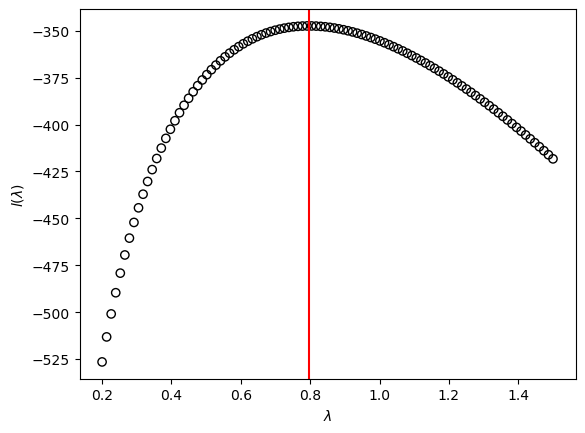

In [34]:
fig, ax = plt.subplots()
ax.scatter(lambda_seq, llk_lambda, facecolors="none", edgecolors="black")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$l(\lambda)$")
ax.axvline(lambda_hat, color="red")
plt.show()

Visually, it is clear that the log likelihood is locally quadratic at its maximum.

This means that it is well approximated by its second order Taylor expansion

$$ l(\lambda) \approx l(\widehat{\lambda}) + \frac{\partial l(\widehat{\lambda})}{\partial \lambda}(\lambda - \widehat{\lambda}) +
\frac{1}{2}\frac{\partial l^2(\widehat{\lambda})}{\partial \lambda^2}\left(\lambda - \widehat{\lambda}\right)^2$$

From our work above, we have all that we need to inspect the accuracy of the approximation,

$$  l(\lambda) = n \log \lambda - \lambda \sum_{i=1} ^n y_i $$
giving the derivative of $l$ as 
$$ \frac{\partial l(\lambda)}{\partial \lambda} =  \frac{n}{\lambda} - \sum_{i=1} ^n y_i, \qquad \frac{\partial l^2(\lambda)}{\partial \lambda^2} = -\frac{n}{\lambda^2}   $$

We can implement this as follows, noting that the first derivative term vanishes at the maximum.

In [35]:
def llk_taylor(rate, lambda_hat, data):
    n = len(data)
    return llk(lambda_hat, data) - 0.5 * n * (lambda_hat - rate)**2 / lambda_hat**2

In [36]:
llk_approx = llk_taylor(lambda_seq, lambda_hat, inter_eq_days)

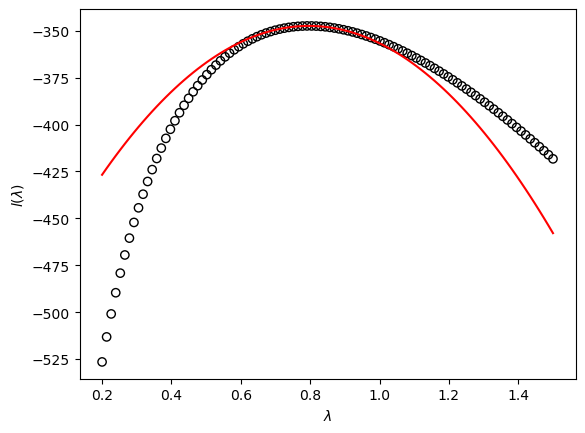

In [37]:
fig, ax = plt.subplots()
ax.scatter(lambda_seq, llk_lambda, facecolors="none", edgecolors="black")
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"$l(\lambda)$")
ax.plot(lambda_seq, llk_approx, color="red")
plt.show()

The quadratic approximation appears good close to the MLE. 
This suggests that the asymptotic results for maximum likelihood estimators should apply. Recall that for large samples, the sampling distribution of the maximum likelihood estimator is approximately normal, centred on the true value,

$$ \widehat{\lambda} \sim N\left(\lambda,\frac{1}{I(\lambda)}  \right), $$
where the Fisher information is

$$ I(\lambda) = E\left[ - \frac{\partial^2 l}{\partial \lambda^2} \right]. $$
In this case

$$ \widehat{\lambda} \sim N\left(\lambda, \frac{\lambda^2}{n} \right). $$
Meaning that we can estimate the standard error of $\widehat{\lambda}$ as

In [38]:
lambda_se = lambda_hat / np.sqrt(len(inter_eq_days))

In [39]:
lambda_se

np.float64(0.04733935105955243)

Using this result, we can make an approximate 95\% confidence interval for $\lambda$ as

In [40]:
lambda_hat + np.array([-1, 1]) *1.96*lambda_se

array([0.70358602, 0.88915628])

# The bootstrap

We can check that all is working as intended using the *bootstrap*. We generate a large number $B$ of synthetic datasets of size $n$ by sampling with replacement from our original data. For each bootstrap sample, we compute the maximum likelihood estimate $\widehat{\lambda}^{*}$.

The idea is that the bootstrap distribution $\widehat{\lambda}_1^{*}, \ldots, \widehat{\lambda}_B^{*}$  is an approximation to the sampling distribution of $\widehat{\lambda}$.

Here we will work with $B = 2000$.

In [41]:
n_boot = 2000
lambda_hat_boot = np.zeros(n_boot)
for i in range(n_boot):
    inter_eq_boot = rng.choice(inter_eq_days, size=len(inter_eq_days), replace=True)
    lambda_hat_boot[i] = 1 / np.mean(inter_eq_boot)

We compare the bootstrap distribution of $\widehat{\lambda}$ with a normal distribution using a Q-Q plot.

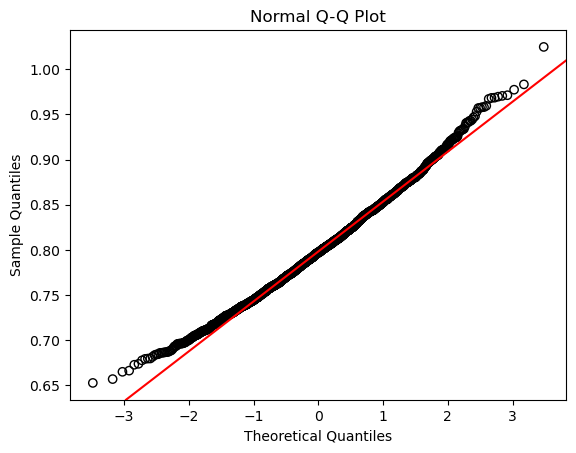

In [42]:
normal_quantiles = norm.ppf(ppoints(n_boot))
fig, ax = plt.subplots()
ax.scatter(normal_quantiles, np.sort(lambda_hat_boot),
           facecolors="none", edgecolors="black")
ax.set_xlabel("Theoretical Quantiles")
ax.set_ylabel("Sample Quantiles")
ax.set_title("Normal Q-Q Plot")


sample_quartiles = np.quantile(lambda_hat_boot, [0.25, 0.75])
normal_quartiles = norm.ppf([0.25, 0.75])
slope = (sample_quartiles[1] - sample_quartiles[0]) / (normal_quartiles[1] - normal_quartiles[0])
intercept = sample_quartiles[0] - slope * normal_quartiles[0]
ax.axline((0, intercept), slope=slope, color="red")
plt.show()

The bootstrap distribution is close to normal, as expected. Its standard deviation is

In [43]:
np.std(lambda_hat_boot, ddof=1)

np.float64(0.053879461595355525)

Close to the value predicted by the asymptotic theory.

We can also compare the central 95\% of the bootstrap distribution with the endpoints of the approximate confidence interval computed above.

In [44]:
np.quantile(lambda_hat_boot, [0.025, 0.975])

array([0.70294578, 0.91243587])

A good match between the asymptotic confidence interval and the bootstrap sampling distribution.

# Supplementary reading (for interest)

Really, the model proposed here is quite simplistic: in this dataset, we're mostly seeing noise. If the topic is of interest, you might enjoy the article below, which goes a lot further.

[Ogata, Yosihiko. "Statistical models for earthquake occurrences and residual analysis for point processes." Journal of the American Statistical association 83.401 (1988): 9-27.](https://www.tandfonline.com/doi/abs/10.1080/01621459.1988.10478560)